# Лабораторная 2 Часть 1 Конвейер Pandas

**Иноземцев Сергей Викторович · ЕТ-216 · вариант 11**

Источник задания: «Лб2 (ч1).pdf». Все вычисления воспроизводимы при последовательном запуске ячеек. Фиксированные random seed заданы в коде.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown
pd.set_option('display.max_columns', 25)
pd.set_option('display.max_rows', 25)
sns.set_theme(style='whitegrid', font='DejaVu Sans')
plt.rcParams.update({'figure.figsize': (9, 5), 'figure.dpi': 110})
BASE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'datasets'/'StudentsPerformance.csv').is_file())
DATA = BASE/'datasets'
FIG = Path('figures'); FIG.mkdir(exist_ok=True)
def show(name):
    plt.tight_layout()
    plt.savefig(FIG/(name+'.png'), bbox_inches='tight')
    plt.show()

## Формирование и сохранение данных
Создать 15 заказов из условия и сохранить CSV без индекса.

In [2]:
raw_data={'order_id':list(range(1001,1016)),
'channel':['site','app','app','marketplace','site','app','site','marketplace','app','site','marketplace','app','site','site','marketplace'],
'order_sum':[1200,2500,1800,3200,900,1500,2800,45000,2100,1700,3600,1100,2400,1900,3300],
'delivery_time':[25,np.nan,40,55,20,30,np.nan,70,35,45,50,18,27,np.nan,60],
'rating':[5,4,5,3,5,4,2,1,5,4,3,5,4,5,2]}
df=pd.DataFrame(raw_data);df.to_csv('online_store_orders.csv',index=False);display(df)

,order_id,channel,order_sum,delivery_time,rating
0,1001,site,1200,25.0,5
1,1002,app,2500,NaN,4
2,1003,app,1800,40.0,5
3,1004,marketplace,3200,55.0,3
4,1005,site,900,20.0,5
5,1006,app,1500,30.0,4
6,1007,site,2800,NaN,2
7,1008,marketplace,45000,70.0,1
8,1009,app,2100,35.0,5
9,1010,site,1700,45.0,4


index=False исключает технический индекс строк из CSV. Без него при обратной загрузке появился бы дополнительный столбец Unnamed: 0.

## Загрузка и первичная проверка

In [3]:
store_df=pd.read_csv('online_store_orders.csv')
display(store_df.head());display(store_df.tail());print(store_df.shape,store_df.columns.tolist());store_df.info()
display(store_df.isna().sum());display(store_df.describe())
assert store_df.shape==(15,5)

,order_id,channel,order_sum,delivery_time,rating
0,1001,site,1200,25.0,5
1,1002,app,2500,NaN,4
2,1003,app,1800,40.0,5
3,1004,marketplace,3200,55.0,3
4,1005,site,900,20.0,5


,order_id,channel,order_sum,delivery_time,rating
10,1011,marketplace,3600,50.0,3
11,1012,app,1100,18.0,5
12,1013,site,2400,27.0,4
13,1014,site,1900,NaN,5
14,1015,marketplace,3300,60.0,2


(15, 5) ['order_id', 'channel', 'order_sum', 'delivery_time', 'rating']
<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   order_id       15 non-null     int64  
 1   channel        15 non-null     str    
 2   order_sum      15 non-null     int64  
 3   delivery_time  12 non-null     float64
 4   rating         15 non-null     int64  
dtypes: float64(1), int64(3), str(1)
memory usage: 732.0 bytes


order_id         0
channel          0
order_sum        0
delivery_time    3
rating           0
dtype: int64

,order_id,order_sum,delivery_time,rating
count,15.000000,15.00000,12.000000,15.000000
mean,1008.000000,5000.00000,39.583333,3.800000
std,4.472136,11096.33144,16.654010,1.320173
min,1001.000000,900.00000,18.000000,1.000000
25%,1004.500000,1600.00000,26.500000,3.000000
50%,1008.000000,2100.00000,37.500000,4.000000
75%,1011.500000,3000.00000,51.250000,5.000000
max,1015.000000,45000.00000,70.000000,5.000000


15 строк, 5 столбцов. Числовые: order_id, order_sum, delivery_time, rating. Три пропуска находятся только в delivery_time; channel — категориальный признак. Максимальная сумма 45000 заметно превосходит остальные заказы.

## Выборка и фильтрация

In [4]:
display(store_df[['order_sum','delivery_time']])
display(store_df.iloc[3:8,store_df.columns.get_indexer(['order_sum','delivery_time'])])
premium_orders=store_df[(store_df.order_sum>2000)&(store_df.rating==5)];display(premium_orders)

,order_sum,delivery_time
0,1200,25.0
1,2500,NaN
2,1800,40.0
3,3200,55.0
4,900,20.0
5,1500,30.0
6,2800,NaN
7,45000,70.0
8,2100,35.0
9,1700,45.0


,order_sum,delivery_time
3,3200,55.0
4,900,20.0
5,1500,30.0
6,2800,NaN
7,45000,70.0


,order_id,channel,order_sum,delivery_time,rating
8,1009,app,2100,35.0,5


iloc[3:8] включает индексы от 3 до 7. Оператор & объединяет булевы Series поэлементно; and требует единственное логическое значение и для Series неоднозначен. Под фильтр попадает заказ 1009.

## Статистики и группировка

In [5]:
mean_delivery=store_df.delivery_time.mean();median_delivery=store_df.delivery_time.median()
print('Доставка среднее/медиана:',mean_delivery,median_delivery)
display(store_df.rating.value_counts())
store_df['is_high_value']=store_df.order_sum>3000
display(store_df[['order_id','order_sum','is_high_value']])
channel_stats=store_df.groupby('channel').order_sum.mean().sort_values(ascending=False);display(channel_stats)
print('Высокая стоимость:',store_df.is_high_value.sum())
print('Средняя сумма с выбросом/без:',store_df.order_sum.mean(),store_df.loc[store_df.order_sum<45000,'order_sum'].mean())

Доставка среднее/медиана: 39.583333333333336 37.5


rating
5    6
4    4
3    2
2    2
1    1
Name: count, dtype: int64

,order_id,order_sum,is_high_value
0,1001,1200,False
1,1002,2500,False
2,1003,1800,False
3,1004,3200,True
4,1005,900,False
5,1006,1500,False
6,1007,2800,False
7,1008,45000,True
8,1009,2100,False
9,1010,1700,False


channel
marketplace    13775.000000
site            1816.666667
app             1800.000000
Name: order_sum, dtype: float64

Высокая стоимость: 4
Средняя сумма с выбросом/без: 5000.0 2142.8571428571427


В наборе 15 заказов и 3 пропуска времени доставки; среднее время 39.58 мин, медиана 37.50 мин (пропуски исключены). Средняя сумма по каналам: marketplace: 13775.00 руб.; site: 1816.67 руб.; app: 1800.00 руб. Четыре заказа дороже 3000 руб. Заказ на 45000 руб. сильно повышает среднее marketplace; это не доказывает преимущество типичного заказа этого канала. Чаще всего встречается оценка 5. Среднее чувствительнее медианы к экстремальным значениям.

## Дополнительное задание Гистограмма

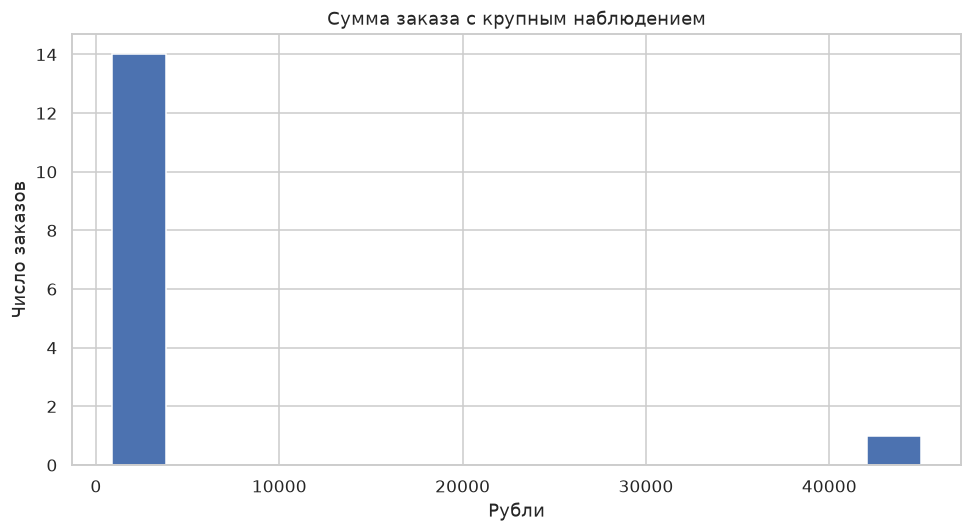

In [6]:
store_df.order_sum.plot.hist(bins=15);plt.title('Сумма заказа с крупным наблюдением');plt.xlabel('Рубли');plt.ylabel('Число заказов');show('order_sum')

Заказ 45000 растягивает ось и сжимает основную массу распределения. Для дополнительной детализации полезны логарифмическая ось или отдельный график основной группы, но исходное наблюдение нельзя удалять без проверки.